# Q1 - Verified RAW-FABRID data and train-only EDA
The lecturer notebooks inspire loading, visualisation and tensor inspection. All assessed results use RAW-FABRID, never MNIST/CIFAR. This notebook reads the immutable full study and verifies the included authentic sample without requiring the 4 GB download.

In [1]:
from pathlib import Path
import sys, json
PROJECT = Path.cwd()
if PROJECT.name == 'notebooks': PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT / 'src'))
from fabric_inspector.common import read_json
from IPython.display import display, Image as DisplayImage, Markdown
import pandas as pd
def read(path): return read_json(PROJECT / path)
def figure(path): display(DisplayImage(filename=str(PROJECT / path)))


In [2]:
from fabric_inspector.data.manifest import REAL
full = read('data/manifests/split.json')
assert full['provenance'] == REAL
frame = pd.read_csv(PROJECT/'data/manifests/split.csv')
assert len(frame)==19852
display(frame.groupby('split').agg(patches=('patch_id','size'), defective=('label','sum'), sources=('source_id','nunique')))
print(full['split_sha256'])

af7daf13d0854ceeba004f1a06182bac778ac716021dec3d8fc40edf265aa76f


,patches,defective,sources
split,,,
test,2996,96,107
train,13384,539,478
val,3472,52,124


In [3]:
for key in ['source_id','group_id','verified_extra_group']:
    assert frame.groupby(key)['split'].nunique().max()==1
print('Source, duplicate-component and publisher-origin separation passed')
display(read('data/manifests/data-audit.json'))

Source, duplicate-component and publisher-origin separation passed


{'created_at': '2026-10-11T15:50:51.832344+00:00',
 'provenance': 'RAW-FABRID_V1',
 'data_root': '../raw/release/RAW_FABRID',
 'rows_csv': 'split.csv',
 'split_sha256': 'af7daf13d0854ceeba004f1a06182bac778ac716021dec3d8fc40edf265aa76f',
 'seed': 42,
 'integrity_only_split_draws': 128,
 'selected_draw': 32,
 'requested_ratios': [0.7, 0.15, 0.15],
 'audit': {'near_candidate_pairs_checked': 324109,
  'near_match_pairs_joined': 0,
  'near_full_pixel_checks': 7587,
  'exact_duplicate_count': 0,
  'duplicate_limitations': 'No guarantee for rotations, nonidentical crops, or unrecorded rolls',
  'metadata_sha256': 'a32dc5c746d36908e88cb44a27c66eec718a3266e5c658066fb8c31c410ea914',
  'verified_patch_counts': {'0': 19165, '1': 687},
  'source_images': 709,
  'label_definition': 'At least one exact-white (255) annotated defect pixel; normal status explicitly confirmed',
  'mask_policy': 'Intermediate edge intensities excluded; exact 255 agrees with publisher CSV defect areas. Raw mask bytes prese

In [4]:
from fabric_inspector.data.manifest import load_manifest
sample, rows, root = load_manifest(PROJECT/'data/sample-manifests/split.json', verify_files=True)
assert len(rows)==168
print(sample['provenance'], len(rows), 'authentic engineering images; no sample performance claim')

RAW-FABRID_V1_REPRESENTATIVE_SAMPLE 168 authentic engineering images; no sample performance claim


{'partition': 'train',
 'provenance': 'RAW-FABRID_V1',
 'split_sha256': 'af7daf13d0854ceeba004f1a06182bac778ac716021dec3d8fc40edf265aa76f',
 'patches': 13384,
 'positives': 539,
 'positive_fraction': 0.040271966527196654,
 'independent_groups': 4,
 'source_images': 478,
 'source_images_containing_positive_patches': 146,
 'defect_area_fraction_quantiles': {'min': 1.52587890625e-05,
  'q25': 0.013916015625,
  'median': 0.0471954345703125,
  'q75': 0.06044769287109375,
  'max': 0.22369384765625},
 'brightness_range': [68.59941101074219, 222.099365234375],
 'contrast_range': [29.350550397105888, 57.262533240877175],
 'texture_total_variation_range': [29.575045955882352, 82.30418198529412],
 'group_metadata_limit': 'Publisher roll_id is an anonymised fabric-origin field joined through HighRes metadata; groups are conservatively kept intact. Beyond this field, physical-roll, fabric-type and manufacturer relationships are not established.'}

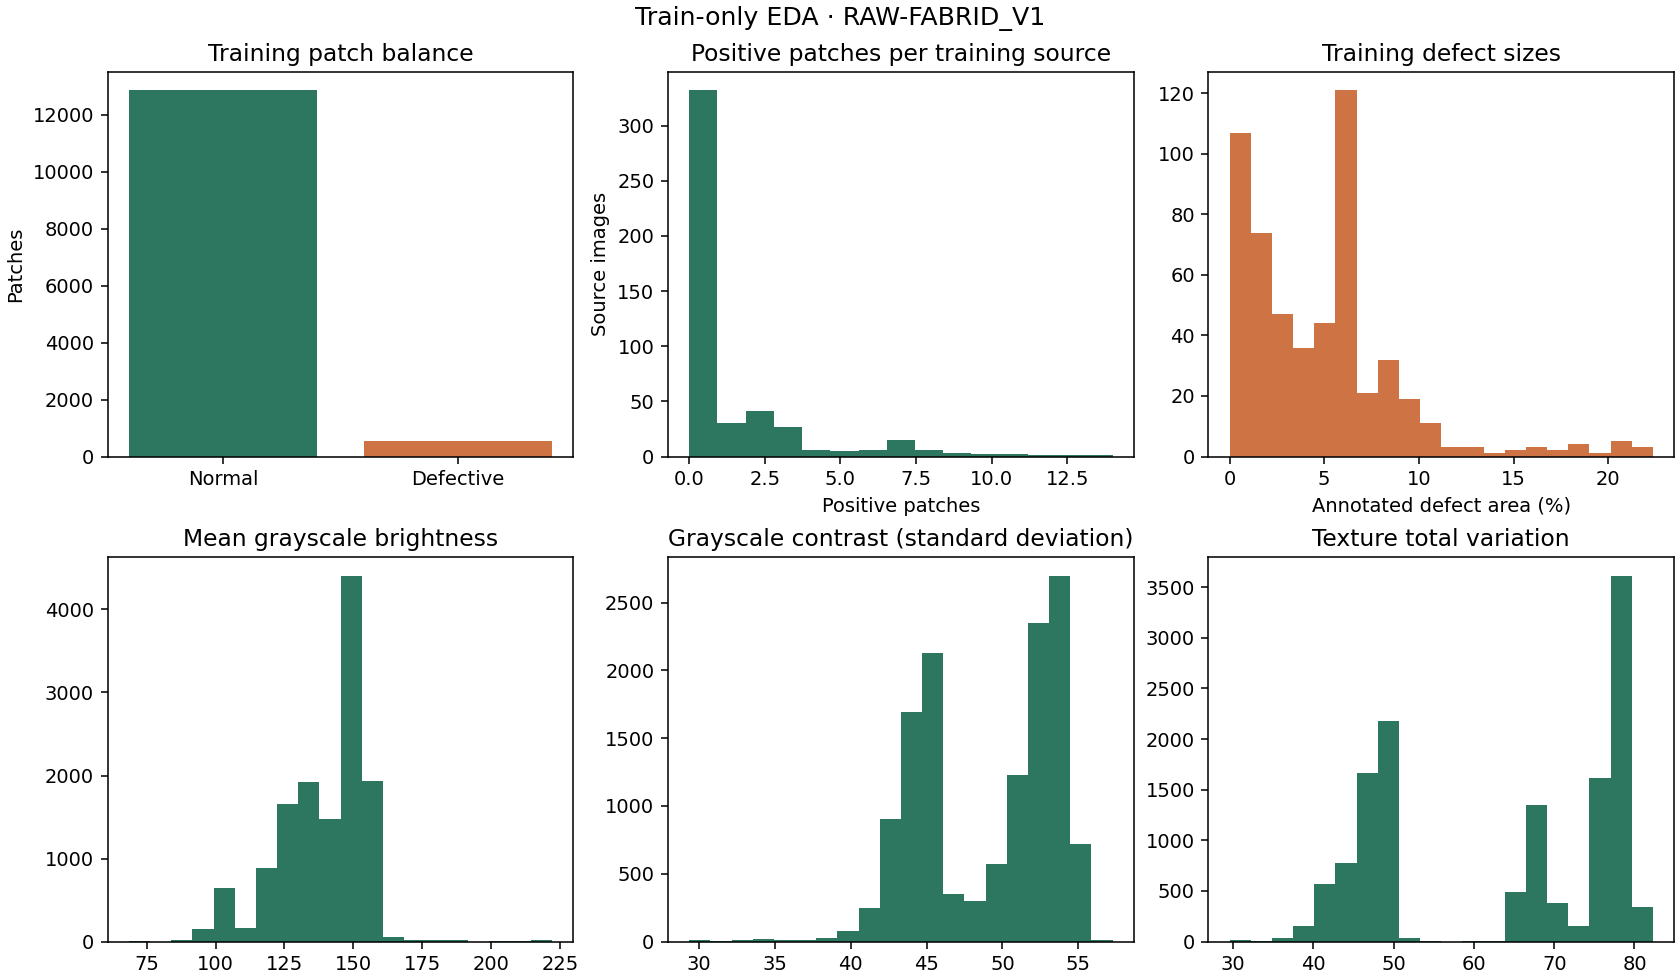

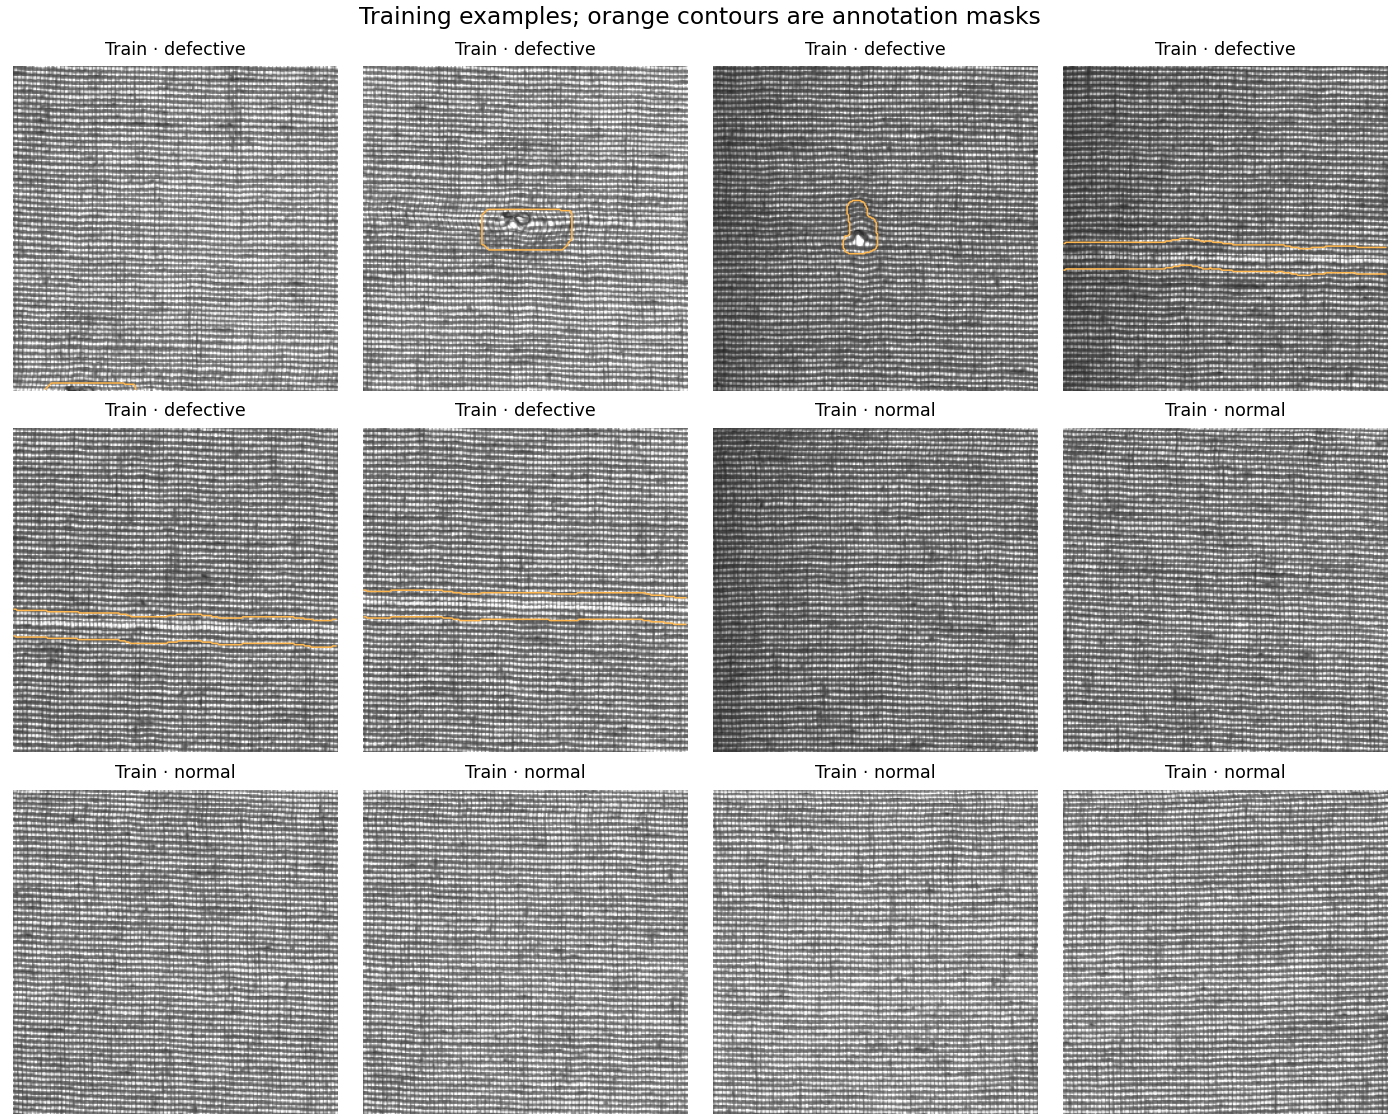

{'provenance': 'RAW-FABRID_V1',
 'findings': [{'finding': 'Training has 539/13384 defective patches (4.0%).',
   'constraint': 'Compare weighted and unweighted BCE; retain both trivial references and defect-class F2.',
   'evidence': 'train class counts; no test image inspection'},
  {'finding': 'The smallest observed training defect covers 0.002% of a 256x256 patch.',
   'constraint': 'Preserve the patch resolution and avoid cropping/downsampling that can erase small defects; examine coarse CAM limits.',
   'evidence': 'verified training binary masks'},
  {'finding': '13384 training patches come from 478 source images and 4 independent components.',
   'constraint': 'Restrict CNN capacity, test transfer learning, and use component bootstrap rather than patch-independent uncertainty.',
   'evidence': 'immutable source/duplicate manifest'}]}

In [5]:
display(read('docs/eda-statistics.json'))
figure('reports/figures/eda-summary.png')
figure('reports/figures/eda-training-examples.png')
display(read('docs/eda-modelling-findings.json'))

Three constraints: low defect prevalence requires recall-sensitive F2 and weighting; tiny regions require unchanged 256x256 detail; four training origin groups require modest capacity and group isolation. Exact-white mask foreground matches all 687 CSV areas. Origin IDs do not establish physical roll/manufacturer identities.